# Exploratory Data Analysis (EDA) — Complete Course Notebook

**A hands-on, module-based course covering Univariate, Bivariate, and Multivariate Analysis, Feature Importance, a Mini Project, and a Final Assessment.**

Dataset used throughout: the classic **Titanic** dataset (loaded via `seaborn`), which contains a mix of numerical and categorical features and a binary target (`survived`) — ideal for demonstrating every EDA technique in this course.

Run all cells in order (Colab: *Runtime → Run all*).


---
# Module 1 — Introduction

## 1.1 Learning Objectives

By the end of this module, you will be able to:
- Explain what Exploratory Data Analysis (EDA) is and why it matters
- Describe the dataset used in this course
- Load, inspect, and summarize a dataset in Python


## 1.2 What is EDA?

Exploratory Data Analysis (EDA) is the process of investigating a dataset to summarize its main characteristics, often using statistical summaries and visualizations. It is typically the **first step** after data collection and cleaning, and before formal modeling.

EDA helps answer questions such as:
- What does the data look like?
- Are there missing values or outliers?
- How are variables distributed?
- How do variables relate to each other and to a target variable?


## 1.3 Why EDA is Important

- **Uncovers data quality issues** — missing values, duplicates, inconsistent types, outliers
- **Reveals patterns and relationships** that guide feature engineering and model choice
- **Validates assumptions** required by statistical models (e.g., normality, linearity)
- **Prevents costly mistakes** later in the machine learning pipeline
- **Communicates insights** to stakeholders through clear visuals


## 1.4 Dataset Description

We use the **Titanic** dataset (passenger records from the RMS Titanic, 1912), loaded directly via `seaborn.load_dataset('titanic')`.

| Column | Description |
|---|---|
| survived | Target: 0 = No, 1 = Yes |
| pclass | Ticket class (1, 2, 3) |
| sex | Passenger sex |
| age | Age in years |
| sibsp | # siblings/spouses aboard |
| parch | # parents/children aboard |
| fare | Passenger fare |
| embarked | Port of embarkation |
| class | Passenger class (string) |
| who | man/woman/child |
| alone | Whether the passenger was alone |

This dataset has a healthy mix of numeric, categorical, and missing data — perfect for demonstrating the full EDA workflow.


In [ ]:
# Import core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")
%matplotlib inline
pd.set_option('display.max_columns', None)
print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:
import pandas as pd
import seaborn as sns
# Load the Titanic dataset using seaborn as per course description
df = sns.load_dataset('titanic')
# Keep a clean working copy with commonly used columns
df = df[['survived','pclass','sex','age','sibsp','parch','fare',
         'embarked','class','who','alone']].copy()
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True


In [ ]:
# Dataset overview
print("Shape:", df.shape)
print("\nInfo:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())
print("\nSummary statistics (numeric columns):")
df.describe()


Shape: (891, 11)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   survived  891 non-null    int64   
 1   pclass    891 non-null    int64   
 2   sex       891 non-null    object  
 3   age       714 non-null    float64 
 4   sibsp     891 non-null    int64   
 5   parch     891 non-null    int64   
 6   fare      891 non-null    float64 
 7   embarked  889 non-null    object  
 8   class     891 non-null    category
 9   who       891 non-null    object  
 10  alone     891 non-null    bool    
dtypes: bool(1), category(1), float64(2), int64(4), object(3)
memory usage: 64.6+ KB

Missing values per column:
survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
class         0
who           0
alone         0
dtype: int64

Summary statistics (numeric columns):


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


---
# Module 2 — Univariate Analysis

Univariate analysis examines **one variable at a time** — its central tendency, spread, shape, and distribution. We will use `age` and `fare` as our main continuous variables, and `pclass` / `survived` / `embarked` as categorical examples.


### 2.1 Mean, Median, Mode

In [ ]:
# Central tendency measures for 'age' and 'fare'
for col in ['age', 'fare']:
    print(f"--- {col} ---")
    print("Mean   :", df[col].mean())
    print("Median :", df[col].median())
    print("Mode   :", df[col].mode()[0])
    print()


--- age ---
Mean   : 29.69911764705882
Median : 28.0
Mode   : 24.0

--- fare ---
Mean   : 32.204207968574636
Median : 14.4542
Mode   : 8.05



### 2.2 Variance, Standard Deviation & Range

In [ ]:
for col in ['age', 'fare']:
    print(f"--- {col} ---")
    print("Variance           :", df[col].var())
    print("Standard Deviation :", df[col].std())
    print("Range              :", df[col].max() - df[col].min())
    print()


--- age ---
Variance           : 211.0191247463081
Standard Deviation : 14.526497332334044
Range              : 79.58

--- fare ---
Variance           : 2469.436845743117
Standard Deviation : 49.693428597180905
Range              : 512.3292



### 2.3 Quartiles & Interquartile Range (IQR)

In [ ]:
for col in ['age', 'fare']:
    q1 = df[col].quantile(0.25)
    q2 = df[col].quantile(0.50)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    print(f"--- {col} ---")
    print(f"Q1: {q1:.2f}  Q2 (median): {q2:.2f}  Q3: {q3:.2f}")
    print(f"IQR: {iqr:.2f}")
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    print(f"Outlier bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
    print()


--- age ---
Q1: 20.12  Q2 (median): 28.00  Q3: 38.00
IQR: 17.88
Outlier bounds: [-6.69, 64.81]

--- fare ---
Q1: 7.91  Q2 (median): 14.45  Q3: 31.00
IQR: 23.09
Outlier bounds: [-26.72, 65.63]



### 2.4 Skewness & Kurtosis

In [ ]:
for col in ['age', 'fare']:
    sk = df[col].skew()
    ku = df[col].kurt()
    print(f"--- {col} ---")
    print(f"Skewness: {sk:.3f}  ({'right-skewed' if sk > 0.5 else 'left-skewed' if sk < -0.5 else 'approximately symmetric'})")
    print(f"Kurtosis: {ku:.3f}  ({'heavy-tailed' if ku > 0.5 else 'light-tailed' if ku < -0.5 else 'approximately normal-tailed'})")
    print()


--- age ---
Skewness: 0.389  (approximately symmetric)
Kurtosis: 0.178  (approximately normal-tailed)

--- fare ---
Skewness: 4.787  (right-skewed)
Kurtosis: 33.398  (heavy-tailed)



### 2.5 Histograms

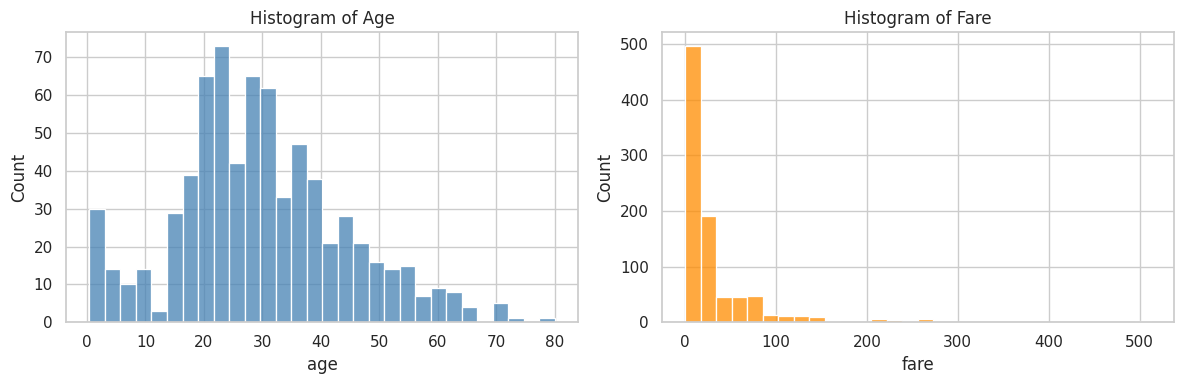

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['age'].dropna(), bins=30, ax=axes[0], color='steelblue')
axes[0].set_title('Histogram of Age')
sns.histplot(df['fare'], bins=30, ax=axes[1], color='darkorange')
axes[1].set_title('Histogram of Fare')
plt.tight_layout()
plt.show()


### 2.6 KDE Plots

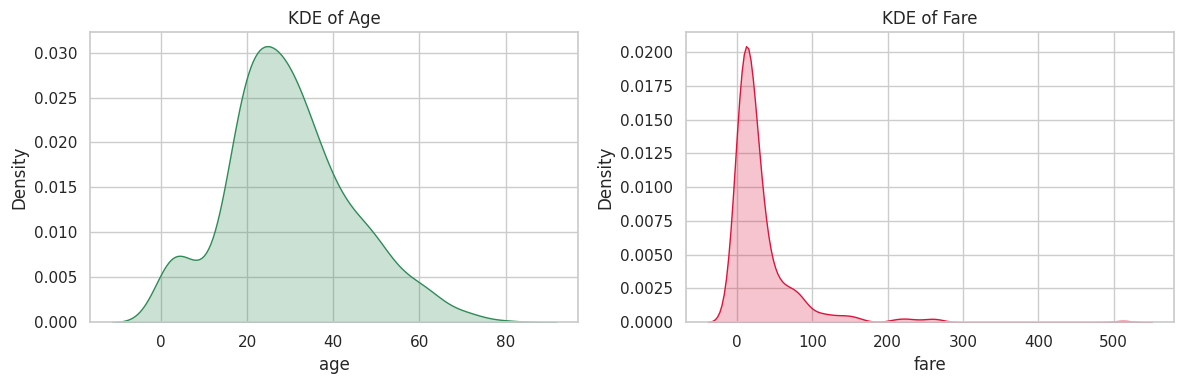

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(df['age'].dropna(), fill=True, ax=axes[0], color='seagreen')
axes[0].set_title('KDE of Age')
sns.kdeplot(df['fare'], fill=True, ax=axes[1], color='crimson')
axes[1].set_title('KDE of Fare')
plt.tight_layout()
plt.show()


### 2.7 Boxplots

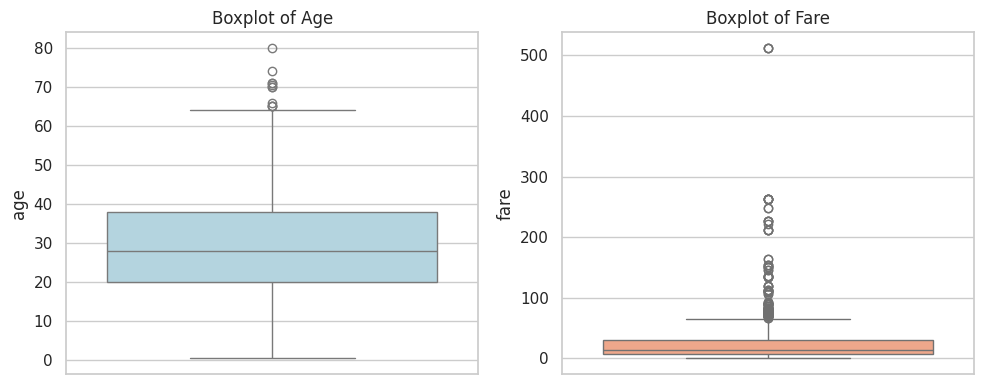

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df['age'], ax=axes[0], color='lightblue')
axes[0].set_title('Boxplot of Age')
sns.boxplot(y=df['fare'], ax=axes[1], color='lightsalmon')
axes[1].set_title('Boxplot of Fare')
plt.tight_layout()
plt.show()


A violin plot is a powerful data visualization tool that combines a standard box plot with a density plot. While box plots only show summary statistics (like the median and quartiles), violin plots display the entire probability density of the data.
When you look at a single "violin", it contains several key visual elements:
The Outer Shape (The Violin): This represents a mirrored Kernel Density Estimation (KDE). The wider the violin body is at a specific value, the more data points cluster at that value.
The Center Black Box/Line: This mimics a mini box plot inside the violin, showing the median (usually a white dot) and the interquartile range (IQR).
The Thin Center Lines (Whiskers): These extend out to show the overall minimum and maximum data values, excluding outliers.

### 2.8 Violin Plots

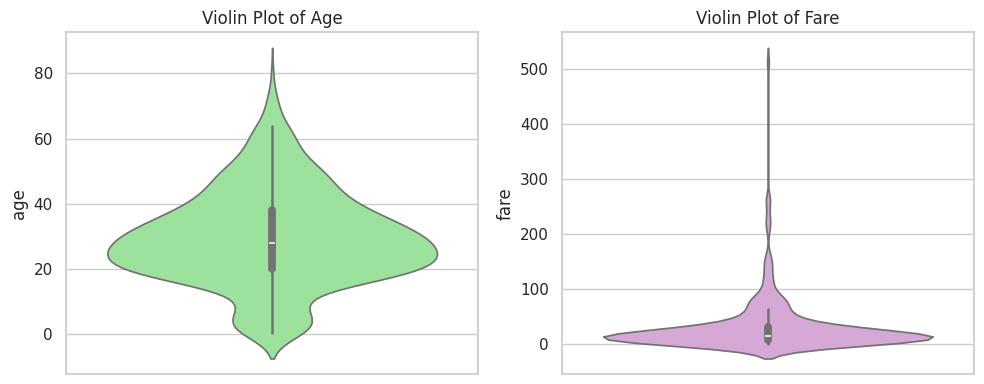

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.violinplot(y=df['age'], ax=axes[0], color='lightgreen')
axes[0].set_title('Violin Plot of Age')
sns.violinplot(y=df['fare'], ax=axes[1], color='plum')
axes[1].set_title('Violin Plot of Fare')
plt.tight_layout()
plt.show()


### 2.9 Count Plots

/tmp/ipykernel_1036/3688167296.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='pclass', data=df, ax=axes[0], palette='viridis')
/tmp/ipykernel_1036/3688167296.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='embarked', data=df, ax=axes[1], palette='magma')


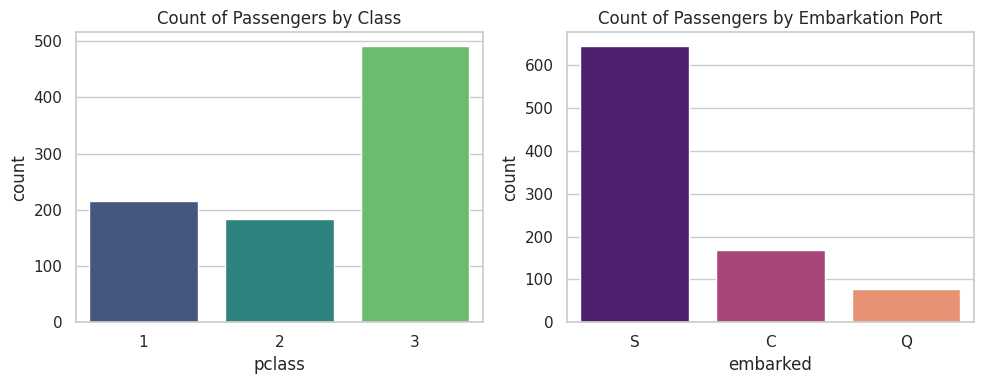

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x='pclass', data=df, ax=axes[0], palette='viridis')
axes[0].set_title('Count of Passengers by Class')
sns.countplot(x='embarked', data=df, ax=axes[1], palette='magma')
axes[1].set_title('Count of Passengers by Embarkation Port')
plt.tight_layout()
plt.show()


### 2.10 Pie Charts

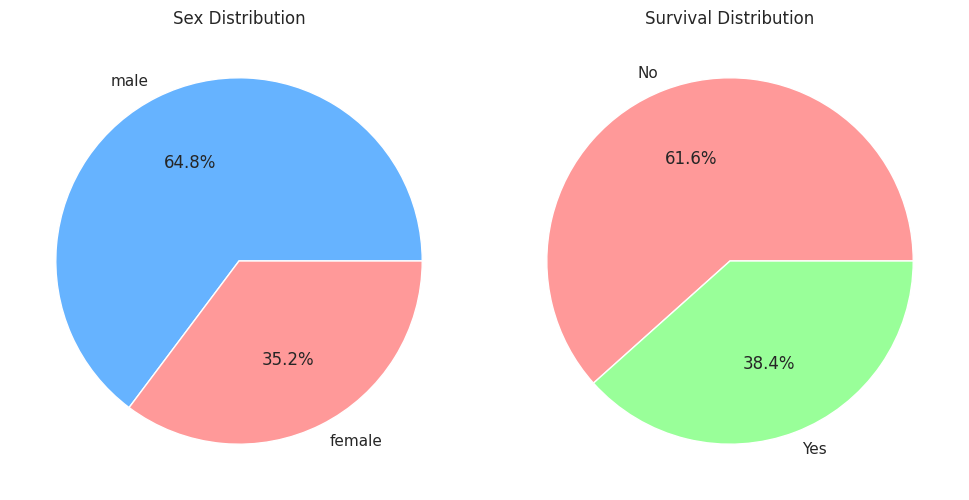

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
df['sex'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[0], colors=['#66b3ff','#ff9999'])
axes[0].set_title('Sex Distribution')
axes[0].set_ylabel('')
df['survived'].value_counts().rename({0:'No',1:'Yes'}).plot.pie(autopct='%1.1f%%', ax=axes[1], colors=['#ff9999','#99ff99'])
axes[1].set_title('Survival Distribution')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()


### 2.11 Bar Charts

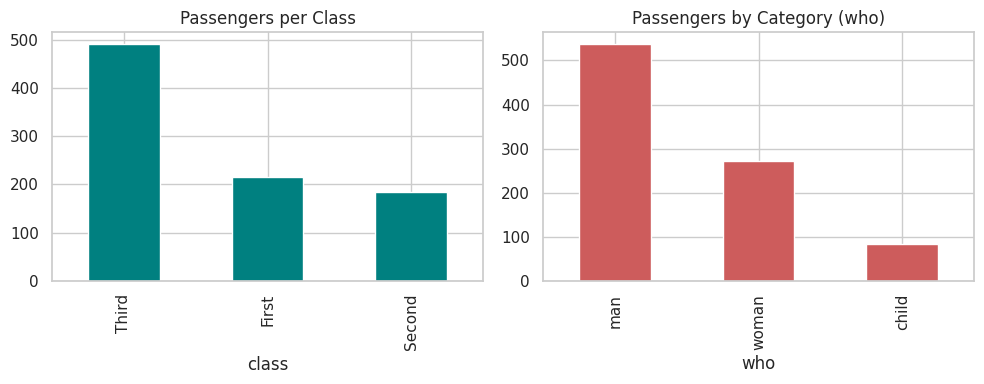

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df['class'].value_counts().plot.bar(ax=axes[0], color='teal')
axes[0].set_title('Passengers per Class')
df['who'].value_counts().plot.bar(ax=axes[1], color='indianred')
axes[1].set_title('Passengers by Category (who)')
plt.tight_layout()
plt.show()


### 2.12 Student Exercises — Module 2

1. Compute the mean, median, and mode of `sibsp` and `parch`. What does the difference between mean and median suggest about the shape of each distribution?
2. Calculate the IQR of `fare`. How many outliers does the 1.5×IQR rule detect?
3. Plot a histogram and KDE for `sibsp`. Is it skewed? In which direction?
4. Create a count plot for `alone`. What proportion of passengers travelled alone?
5. Compare the standard deviation of `age` vs `fare`. Which variable has more relative variability? (Hint: consider the coefficient of variation, std/mean.)


---
# Module 3 — Bivariate Analysis

Bivariate analysis studies the **relationship between two variables** — e.g., how `age` and `fare` relate, or how a numeric feature varies with the target `survived`.


### 3.1 Scatter Plots & Regression Plots

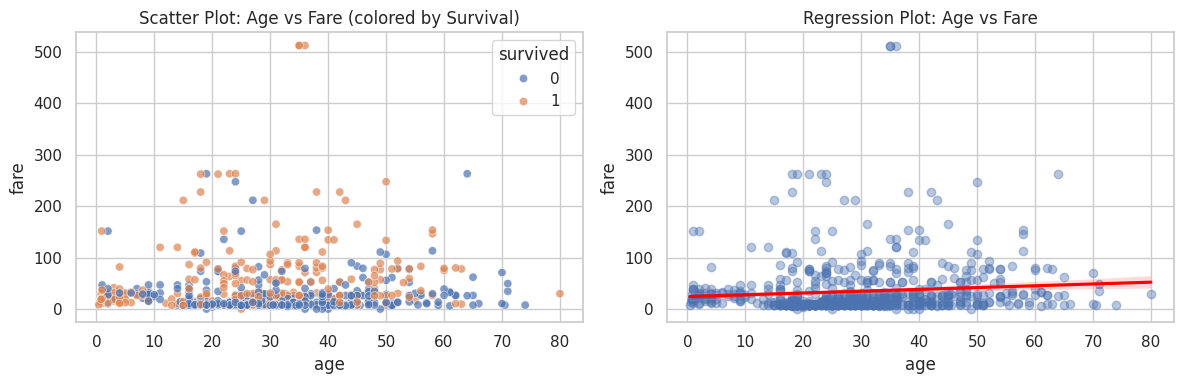

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x='age', y='fare', hue='survived', data=df, ax=axes[0], alpha=0.7)
axes[0].set_title('Scatter Plot: Age vs Fare (colored by Survival)')

sns.regplot(x='age', y='fare', data=df, ax=axes[1], scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
axes[1].set_title('Regression Plot: Age vs Fare')
plt.tight_layout()
plt.show()


### 3.2 Line Plots

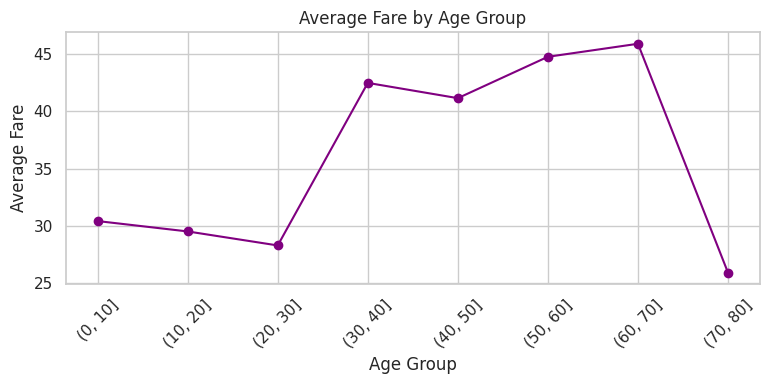

In [ ]:
# Average fare paid by passengers grouped by age (binned) — trend line
age_bins = pd.cut(df['age'], bins=range(0, 90, 10))
fare_by_age = df.groupby(age_bins, observed=True)['fare'].mean()

plt.figure(figsize=(8, 4))
fare_by_age.plot(marker='o', color='purple')
plt.title('Average Fare by Age Group')
plt.ylabel('Average Fare')
plt.xlabel('Age Group')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 3.3 Boxplot & Violin Plot vs Target

/tmp/ipykernel_1036/695905095.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='survived', y='age', data=df, ax=axes[0], palette='Set2')
/tmp/ipykernel_1036/695905095.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='survived', y='fare', data=df, ax=axes[1], palette='Set3')


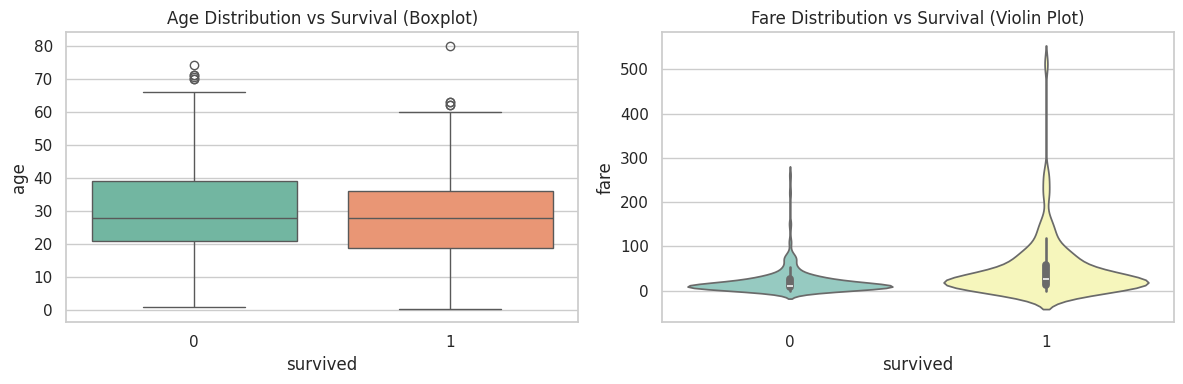

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='survived', y='age', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Age Distribution vs Survival (Boxplot)')

sns.violinplot(x='survived', y='fare', data=df, ax=axes[1], palette='Set3')
axes[1].set_title('Fare Distribution vs Survival (Violin Plot)')
plt.tight_layout()
plt.show()


### 3.4 Pearson Correlation, Spearman Correlation & Covariance

In [ ]:
num_df = df[['age', 'fare', 'sibsp', 'parch', 'survived', 'pclass']].dropna()

pearson_corr = num_df.corr(method='pearson')
spearman_corr = num_df.corr(method='spearman')
covariance = num_df.cov()

print("Pearson Correlation (age vs fare):", num_df['age'].corr(num_df['fare'], method='pearson'))
print("Spearman Correlation (age vs fare):", num_df['age'].corr(num_df['fare'], method='spearman'))
print("Covariance (age vs fare):", num_df['age'].cov(num_df['fare']))
print()
print("Full Pearson correlation matrix:")
pearson_corr


Pearson Correlation (age vs fare): 0.0960666917690389
Spearman Correlation (age vs fare): 0.1350512177342878
Covariance (age vs fare): 73.84902981461926

Full Pearson correlation matrix:


,age,fare,sibsp,parch,survived,pclass
age,1.000000,0.096067,-0.308247,-0.189119,-0.077221,-0.369226
fare,0.096067,1.000000,0.138329,0.205119,0.268189,-0.554182
sibsp,-0.308247,0.138329,1.000000,0.383820,-0.017358,0.067247
parch,-0.189119,0.205119,0.383820,1.000000,0.093317,0.025683
survived,-0.077221,0.268189,-0.017358,0.093317,1.000000,-0.359653
pclass,-0.369226,-0.554182,0.067247,0.025683,-0.359653,1.000000


### 3.5 Crosstabs

In [ ]:
ct = pd.crosstab(df['pclass'], df['survived'], normalize='index')
ct.columns = ['Did Not Survive', 'Survived']
print("Survival rate by Passenger Class:")
ct


Survival rate by Passenger Class:


,Did Not Survive,Survived
pclass,,
1,0.370370,0.629630
2,0.527174,0.472826
3,0.757637,0.242363


### 3.6 Heatmaps

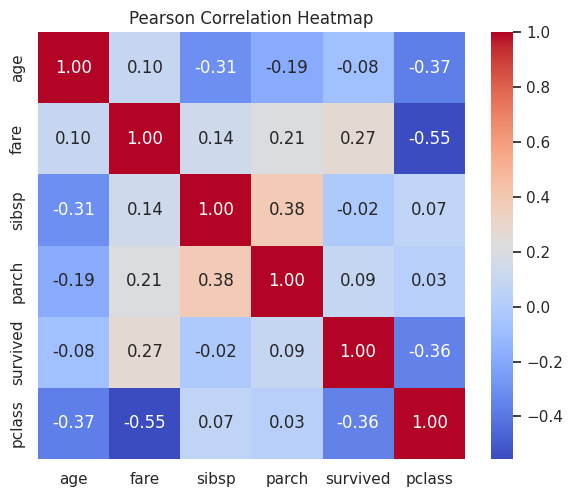

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Pearson Correlation Heatmap')
plt.tight_layout()
plt.show()


### 3.7 Student Activities — Module 3

1. Create a scatter plot of `fare` vs `sibsp`. Is there any visible relationship?
2. Compute the Pearson and Spearman correlation between `pclass` and `fare`. Why might they differ?
3. Build a crosstab of `sex` vs `survived` (normalized). What does it reveal about survival rates by gender?
4. Draw a boxplot of `fare` grouped by `embarked`. Which port had passengers paying the highest fares?
5. Which pair of variables shows the strongest correlation with `survived`? Support your answer with the heatmap.


---
# Module 4 — Multivariate Analysis

Multivariate analysis examines relationships among **three or more variables simultaneously**, helping to uncover complex, joint patterns that bivariate analysis can miss.


### 4.1 Pairplot & Pairwise Relationships

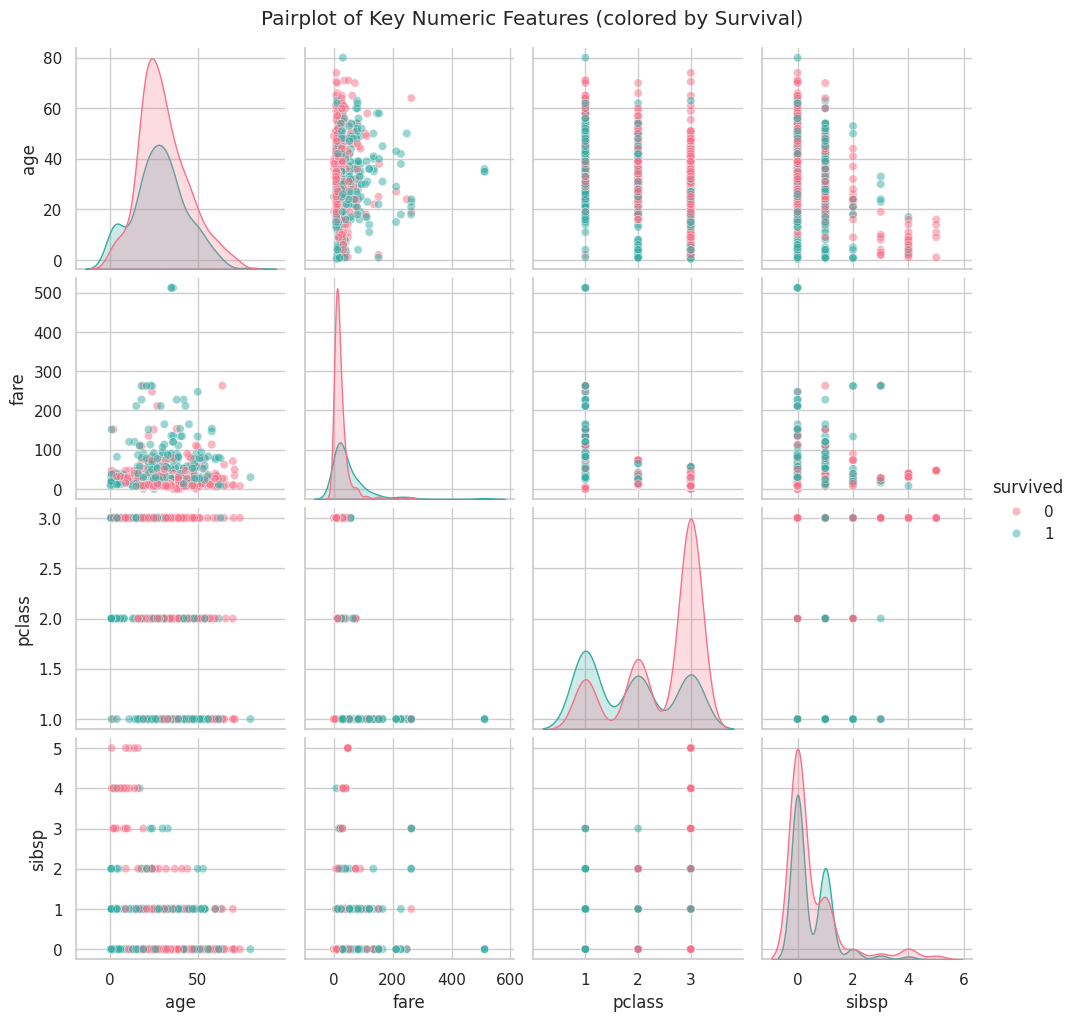

In [ ]:
sns.pairplot(df[['age','fare','pclass','sibsp','survived']].dropna(), hue='survived',
             diag_kind='kde', palette='husl', plot_kws={'alpha':0.5})
plt.suptitle('Pairplot of Key Numeric Features (colored by Survival)', y=1.02)
plt.show()


### 4.2 Correlation Matrix & Heatmap

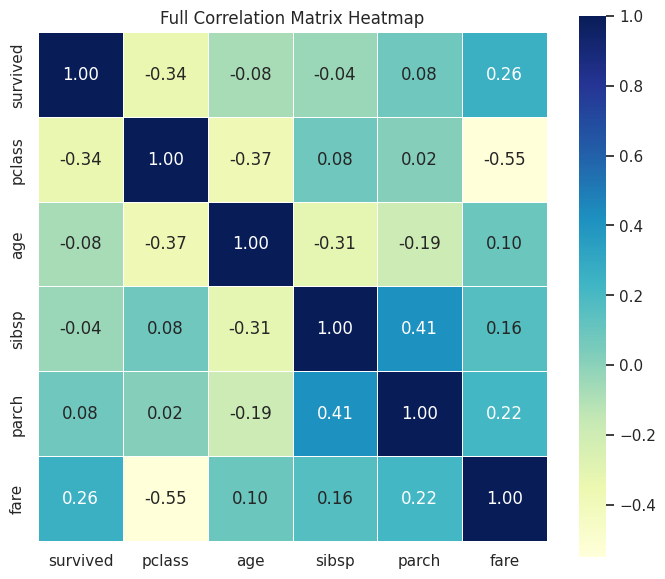

In [ ]:
corr_matrix = df[['survived','pclass','age','sibsp','parch','fare']].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, cmap='YlGnBu', fmt='.2f', square=True, linewidths=0.5)
plt.title('Full Correlation Matrix Heatmap')
plt.tight_layout()
plt.show()


### 4.3 Parallel Coordinates

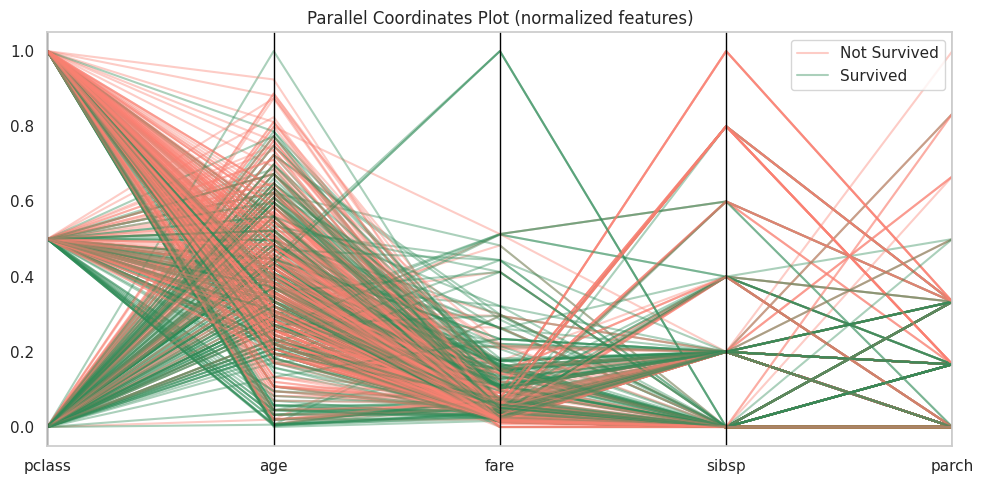

In [ ]:
from pandas.plotting import parallel_coordinates

pc_df = df[['pclass','age','fare','sibsp','parch','survived']].dropna().copy()
pc_df['survived'] = pc_df['survived'].map({0: 'Not Survived', 1: 'Survived'})

# Normalize numeric columns to [0,1] for a readable plot
numeric_cols = ['pclass','age','fare','sibsp','parch']
pc_df_norm = pc_df.copy()
pc_df_norm[numeric_cols] = (pc_df[numeric_cols] - pc_df[numeric_cols].min()) / (pc_df[numeric_cols].max() - pc_df[numeric_cols].min())

plt.figure(figsize=(10, 5))
parallel_coordinates(pc_df_norm, 'survived', color=['salmon', 'seagreen'], alpha=0.4)
plt.title('Parallel Coordinates Plot (normalized features)')
plt.tight_layout()
plt.show()


### 4.4 PCA Visualization

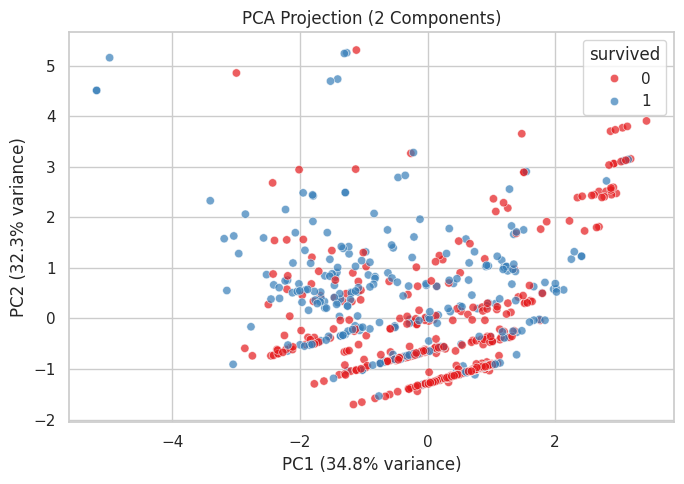

Explained variance ratio: [0.34827175 0.32273262]


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca_df = df[['pclass','age','sibsp','parch','fare','survived']].dropna()
X = pca_df.drop(columns='survived')
y = pca_df['survived']

X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=components[:,0], y=components[:,1], hue=y, palette='Set1', alpha=0.7)
plt.title('PCA Projection (2 Components)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)


### 4.5 3D Scatter Plot

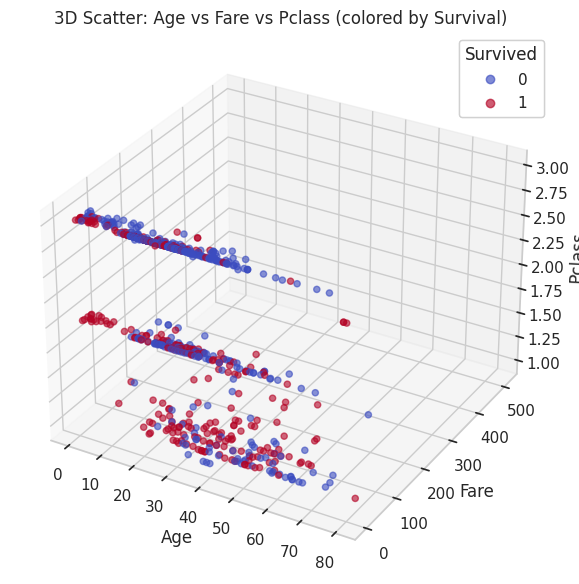

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

plot3d_df = df[['age','fare','pclass','survived']].dropna()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(plot3d_df['age'], plot3d_df['fare'], plot3d_df['pclass'],
                      c=plot3d_df['survived'], cmap='coolwarm', alpha=0.6)
ax.set_xlabel('Age')
ax.set_ylabel('Fare')
ax.set_zlabel('Pclass')
ax.set_title('3D Scatter: Age vs Fare vs Pclass (colored by Survival)')
legend = ax.legend(*scatter.legend_elements(), title="Survived")
ax.add_artist(legend)
plt.tight_layout()
plt.show()


### 4.6 Cluster Map

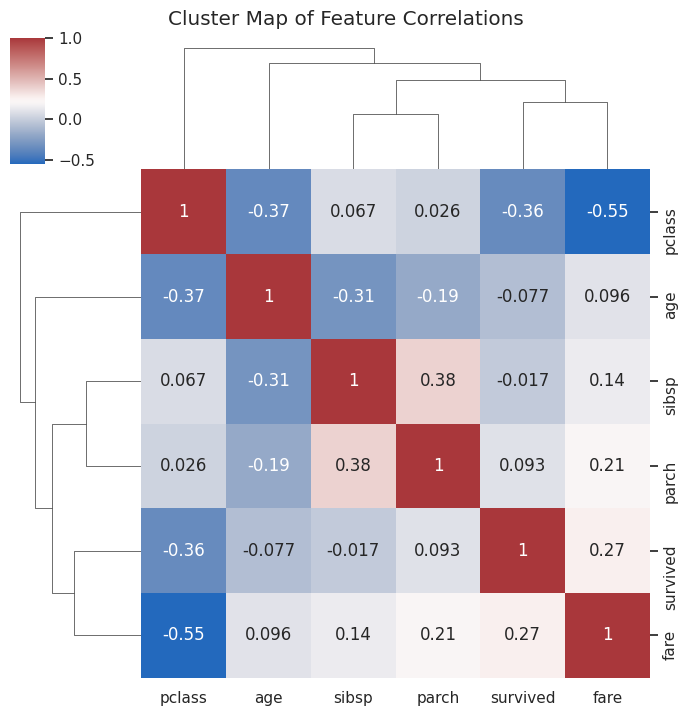

In [ ]:
cluster_df = df[['survived','pclass','age','sibsp','parch','fare']].dropna()
sns.clustermap(cluster_df.corr(), annot=True, cmap='vlag', figsize=(7, 7))
plt.suptitle('Cluster Map of Feature Correlations', y=1.02)
plt.show()


### 4.7 Student Observations — Module 4

Based on the multivariate plots above, answer:

1. In the pairplot, which feature pairs appear to separate survivors from non-survivors most clearly?
2. How much of the total variance do the first two PCA components explain together?
3. In the 3D scatter plot, do lower `pclass` and higher `fare` values visually cluster with higher survival?
4. What does the cluster map suggest about which features tend to move together?
5. Does the parallel coordinates plot suggest `fare` and `pclass` carry overlapping (redundant) information? Why?


---
# Module 5 — Feature Importance

Feature importance techniques rank input variables by how strongly they relate to (or help predict) the target variable — here, `survived`.


### 5.1 Correlation Ranking

In [ ]:
fi_df = df[['survived','pclass','age','sibsp','parch','fare']].dropna()

corr_with_target = fi_df.corr()['survived'].drop('survived').sort_values(key=abs, ascending=False)
print("Features ranked by absolute correlation with 'survived':")
corr_with_target


Features ranked by absolute correlation with 'survived':


,survived
pclass,-0.359653
fare,0.268189
parch,0.093317
age,-0.077221
sibsp,-0.017358


### 5.2 Mutual Information

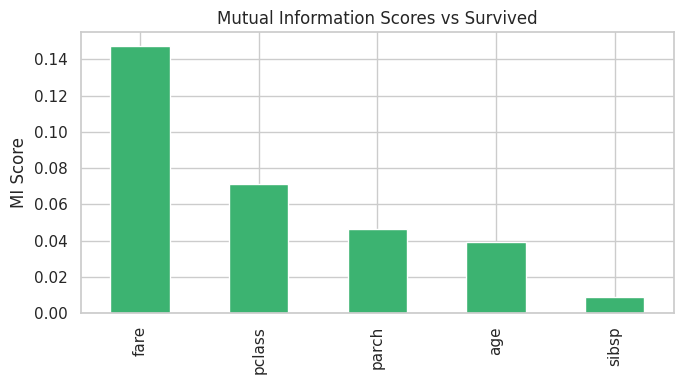

,0
fare,0.147612
pclass,0.071306
parch,0.046405
age,0.039018
sibsp,0.008944


In [ ]:
from sklearn.feature_selection import mutual_info_classif

X_mi = fi_df.drop(columns='survived')
y_mi = fi_df['survived']

mi_scores = mutual_info_classif(X_mi, y_mi, random_state=42)
mi_series = pd.Series(mi_scores, index=X_mi.columns).sort_values(ascending=False)

plt.figure(figsize=(7, 4))
mi_series.plot.bar(color='mediumseagreen')
plt.title('Mutual Information Scores vs Survived')
plt.ylabel('MI Score')
plt.tight_layout()
plt.show()

mi_series


### 5.3 Random Forest Feature Importance

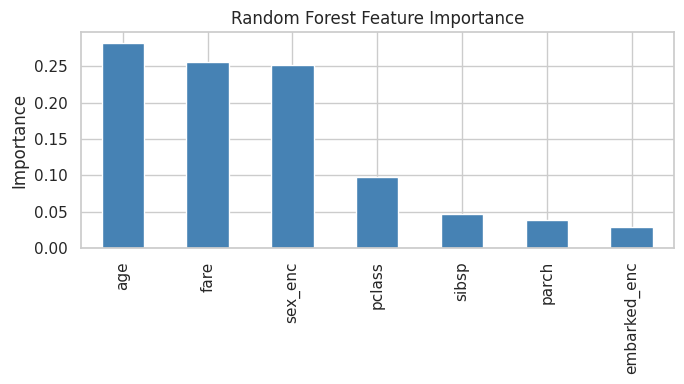

,0
age,0.282403
fare,0.255633
sex_enc,0.251414
pclass,0.097969
sibsp,0.046282
parch,0.037998
embarked_enc,0.028301


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Include encoded categorical features for a richer model
rf_df = df.dropna(subset=['age','fare','embarked']).copy()
rf_df['sex_enc'] = rf_df['sex'].map({'male': 0, 'female': 1})
rf_df['embarked_enc'] = rf_df['embarked'].astype('category').cat.codes

features = ['pclass','age','sibsp','parch','fare','sex_enc','embarked_enc']
X_rf = rf_df[features]
y_rf = rf_df['survived']

rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_rf, y_rf)

importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(7, 4))
importances.plot.bar(color='steelblue')
plt.title('Random Forest Feature Importance')
plt.ylabel('Importance')
plt.tight_layout()
plt.show()

importances


### 5.4 Interpretation

- **Correlation ranking** only captures *linear* relationships and works only on numeric columns.
- **Mutual information** captures both linear and non-linear dependencies, and naturally handles mixed relationships.
- **Random Forest importance** captures non-linear interactions and can include encoded categorical variables (like `sex`), often the single strongest predictor of survival — consistent with historical "women and children first" evacuation policy.

**Takeaway:** Always compare multiple feature-importance methods. Techniques that only capture linear relationships (correlation) may understate the value of categorical or non-linearly related features.


---
# Module 6 — Mini Project

Using everything computed so far, answer the following questions **with evidence** (numbers/plots) from the notebook above. Write your answers in the markdown cell provided after the code cell.

1. Which feature is the most important for predicting `survived`?
2. Which feature contains the highest variability?
3. Which variables are positively correlated?
4. Which variables are negatively correlated?
5. Which variables have outliers?
6. Which variables are skewed?
7. Which features should be selected for prediction?


In [ ]:
# Helper code to support your Mini Project answers

print("=== Q1: Feature Importance Ranking (Random Forest) ===")
print(importances, "\n")

print("=== Q2: Coefficient of Variation (std/mean) — higher = more relative variability ===")
cv = (fi_df.drop(columns='survived').std() / fi_df.drop(columns='survived').mean()).sort_values(ascending=False)
print(cv, "\n")

print("=== Q3 & Q4: Correlation Matrix (sign indicates direction) ===")
print(corr_matrix, "\n")

print("=== Q5: Outlier counts (1.5 x IQR rule) ===")
for col in ['age','fare','sibsp','parch']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {n_outliers} outliers")

print("\n=== Q6: Skewness of numeric variables ===")
print(df[['age','fare','sibsp','parch']].skew())


=== Q1: Feature Importance Ranking (Random Forest) ===
age             0.282403
fare            0.255633
sex_enc         0.251414
pclass          0.097969
sibsp           0.046282
parch           0.037998
embarked_enc    0.028301
dtype: float64 

=== Q2: Coefficient of Variation (std/mean) — higher = more relative variability ===
parch     1.978080
sibsp     1.813840
fare      1.525282
age       0.489122
pclass    0.374772
dtype: float64 

=== Q3 & Q4: Correlation Matrix (sign indicates direction) ===
          survived    pclass       age     sibsp     parch      fare
survived  1.000000 -0.338481 -0.077221 -0.035322  0.081629  0.257307
pclass   -0.338481  1.000000 -0.369226  0.083081  0.018443 -0.549500
age      -0.077221 -0.369226  1.000000 -0.308247 -0.189119  0.096067
sibsp    -0.035322  0.083081 -0.308247  1.000000  0.414838  0.159651
parch     0.081629  0.018443 -0.189119  0.414838  1.000000  0.216225
fare      0.257307 -0.549500  0.096067  0.159651  0.216225  1.000000 

=== Q5: 

### Your Answers (fill in based on the output above)

1. **Most important feature:** *(your answer)*
2. **Highest variability feature:** *(your answer)*
3. **Positively correlated pairs:** *(your answer)*
4. **Negatively correlated pairs:** *(your answer)*
5. **Variables with outliers:** *(your answer)*
6. **Skewed variables:** *(your answer)*
7. **Recommended features for prediction:** *(your answer, with justification)*


---
# Module 7 — Final Assessment

## 7.1 Viva Questions

1. What is the difference between univariate, bivariate, and multivariate analysis?
2. Why is the median preferred over the mean for skewed data?
3. What does a high kurtosis value indicate about a distribution?
4. Explain the difference between Pearson and Spearman correlation. When would you use each?
5. Why is covariance alone insufficient to compare the strength of relationships between different variable pairs?
6. What is the purpose of PCA, and what does "explained variance ratio" mean?
7. Why might Random Forest feature importance differ from a simple correlation ranking?
8. What is the 1.5×IQR rule used for, and what are its limitations?


## 7.2 Lab Questions

1. Load the Titanic dataset and print the number of missing values per column. Which column has the most missing data, and how would you handle it?
2. Generate boxplots for all numeric columns in a single figure using subplots.
3. Compute and interpret the skewness of `fare` before and after applying a log transformation (`np.log1p`).
4. Build a heatmap of the correlation matrix using only passengers who survived. How does it differ from the full-dataset heatmap?
5. Use `mutual_info_classif` to rank features for predicting `pclass` instead of `survived`.


## 7.3 Programming Exercises

1. Write a function `summary_stats(df, col)` that returns a dictionary containing mean, median, mode, variance, std, skewness, and kurtosis for a given column.
2. Write a function that takes a DataFrame and returns a list of columns considered "highly skewed" (|skew| > 1).
3. Implement outlier detection using the Z-score method (|z| > 3) and compare the results with the IQR method for the `fare` column.
4. Write code to automatically generate histograms for every numeric column in a DataFrame using a loop and `plt.subplots`.
5. Implement a simple feature-selection function that keeps only features whose absolute correlation with the target exceeds a given threshold.


## 7.4 Assignment Questions

1. Choose a different dataset (e.g., `sns.load_dataset('tips')` or `sns.load_dataset('diamonds')`) and repeat Modules 2–5 in full.
2. Write a 1-page report (markdown cell) summarizing the key EDA insights you found, including at least 3 visualizations and 3 statistical findings.
3. Compare feature importance rankings from correlation, mutual information, and Random Forest for your chosen dataset. Discuss any disagreements between the methods and why they might occur.
4. Propose a final list of 3–5 features you would use to build a predictive model, with justification based on your EDA.


---
## End of Course

Congratulations on completing this Exploratory Data Analysis course! You have practiced:
- Descriptive statistics and distribution analysis (Module 2)
- Relationships between pairs of variables (Module 3)
- Multivariate patterns and dimensionality reduction (Module 4)
- Feature importance techniques (Module 5)
- Applying everything in a mini project (Module 6)
- Reinforcing your knowledge through assessment (Module 7)

**Next steps:** Use these insights to guide feature engineering and model selection in a machine learning pipeline.
